# Livrable 1 - Classification binaire Photo / Autre

## Projet TouNum

Ce notebook construit un prototype supervisé capable de distinguer une photographie des autres types d’images numérisées.

Le résultat de ce module servira ensuite à orienter les images :

- les photographies pourront être transmises au module de captioning ;
- les autres images seront écartées ou orientées vers un traitement adapté.

## Groupe 2

1. ARMAND Chloé
2. OUBA Hamza
3. CHAOUCHE Ylies
4. FRAIOLI Enzo

**Objectif du livrable :** concevoir, comparer et évaluer des réseaux de neurones convolutifs capables de distinguer une photographie de tout autre type d’image du dataset.

## Problématique et hypothèses

Le dataset contient cinq catégories d’origine :

- Photo ;
- Painting ;
- Schematics ;
- Sketch ;
- Text.

Pour le Livrable 1, nous regroupons les quatre dernières catégories dans la classe **Autre**.

La question étudiée est la suivante :

> Un réseau de neurones convolutif peut-il distinguer correctement les photographies des autres images, y compris les peintures qui peuvent leur ressembler visuellement ?

Nous suivrons le protocole appris dans les Workshops :

1. explorer les données ;
2. séparer entraînement, validation et test ;
3. normaliser les images ;
4. entraîner un CNN ;
5. comparer une version de référence et une version régularisée ;
6. choisir le modèle sur la validation ;
7. évaluer une seule fois sur le test final ;
8. analyser les erreurs par classe d’origine.

## Méthode expérimentale

Le protocole est conçu pour éviter la fuite de données :

- l’entraînement sert à apprendre les poids ;
- la validation sert à comparer les modèles et choisir le seuil ;
- le test reste inconnu jusqu’au bilan final.

La métrique principale de sélection sera le **F1 macro**, car le dataset est déséquilibré. L’accuracy seule serait trompeuse : un modèle prédisant toujours Autre obtiendrait déjà une accuracy élevée.

Nous utiliserons :

- TensorFlow / Keras pour le CNN ;
- NumPy et Pandas pour les données ;
- Matplotlib pour les visualisations ;
- scikit-learn pour les métriques et les matrices de confusion.

In [58]:
from pathlib import Path
from time import perf_counter
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

SEED = 42
keras.utils.set_random_seed(SEED)

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
MAX_EPOCHS = 40
DATA_FRACTION = 1.0
AUTOTUNE = tf.data.AUTOTUNE
DECISION_THRESHOLD = 0.5

# Détection du système et du périphérique d'entraînement.
SYSTEM_NAME = platform.system()
MACHINE_NAME = platform.machine()
AVAILABLE_GPUS = tf.config.list_physical_devices("GPU")

if SYSTEM_NAME == "Darwin":
    BACKEND_NAME = "Metal"
    if AVAILABLE_GPUS:
        TRAINING_DEVICE = "/GPU:0"
        GPU_MESSAGE = "GPU Apple détecté : le plugin tensorflow-metal peut être utilisé."
    else:
        TRAINING_DEVICE = "/CPU:0"
        GPU_MESSAGE = (
            "Aucun GPU Metal détecté. Installez tensorflow-metal dans cet environnement."
        )
elif SYSTEM_NAME == "Windows":
    BACKEND_NAME = "CUDA / GPU TensorFlow"
    if AVAILABLE_GPUS:
        TRAINING_DEVICE = "/GPU:0"
        GPU_MESSAGE = "GPU détecté : TensorFlow pourra l'utiliser si CUDA est correctement installé."
    else:
        TRAINING_DEVICE = "/CPU:0"
        GPU_MESSAGE = (
            "Aucun GPU TensorFlow détecté. Sous Windows, utilisez de préférence WSL2 + CUDA."
        )
else:
    BACKEND_NAME = "CUDA / GPU TensorFlow si disponible"
    TRAINING_DEVICE = "/GPU:0" if AVAILABLE_GPUS else "/CPU:0"
    GPU_MESSAGE = (
        "GPU TensorFlow détecté." if AVAILABLE_GPUS
        else "Aucun GPU TensorFlow détecté : exécution sur CPU."
    )

print("Système :", SYSTEM_NAME, MACHINE_NAME)
print("Backend visé :", BACKEND_NAME)
print("GPU TensorFlow détecté(s) :", AVAILABLE_GPUS)
print("Périphérique d'entraînement :", TRAINING_DEVICE)
print(GPU_MESSAGE)

print("TensorFlow :", tf.__version__)
print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)

Système : Linux x86_64
Backend visé : CUDA / GPU TensorFlow si disponible
GPU TensorFlow détecté(s) : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Périphérique d'entraînement : /GPU:0
GPU TensorFlow détecté.
TensorFlow : 2.22.0-rc0
NumPy : 2.5.3
Pandas : 3.0.6


## 1. Localisation du dataset

Le notebook cherche automatiquement le dataset dans les emplacements utilisés par le projet.

Le dataset complet est privilégié pour le rendu final. Le dossier data_10pct peut servir à faire un essai rapide si le temps de calcul est limité, mais les résultats finaux doivent être produits sur le dataset complet.

In [ ]:
USE_REDUCED_DATASET = False
DATASET_FOLDER = "data_10pct" if USE_REDUCED_DATASET else "data"

print("Dossier d'exécution :", Path.cwd())

DATA_CANDIDATES = [
    Path.home() / "projet" / "Projet" / "Livrable1" / DATASET_FOLDER,
    Path("Projet/Livrable1") / DATASET_FOLDER,
    Path("../Livrable1") / DATASET_FOLDER,
    Path.cwd() / "Projet" / "Livrable1" / DATASET_FOLDER,
]

DATA_DIR = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Dataset introuvable. Lancez le notebook depuis la racine du projet ou Projet/Livrable1_new.")

DATA_DIR = DATA_DIR.resolve()
print("Dataset utilisé :", DATA_DIR)
print("Jeu réduit activé :", USE_REDUCED_DATASET)

SOURCE_CLASSES = ["Painting", "Photo", "Schematics", "Sketch", "Text"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

Dossier d'exécution : /home/ylies/projet/Projet/Livrable1
Dataset utilisé : /home/ylies/projet/Projet/Livrable1/data
Jeu réduit activé : False


## 2. Inventaire et étiquetage

La classe binaire est définie ainsi :

- Photo correspond au label 1 ;
- toutes les autres classes correspondent au label 0.

Nous conservons aussi la classe originale afin de pouvoir mesurer spécifiquement les difficultés liées aux peintures, aux schémas, aux dessins et au texte.

In [ ]:
records = []

for source_class in SOURCE_CLASSES:
    class_dir = DATA_DIR / source_class
    if not class_dir.exists():
        raise FileNotFoundError(f"Dossier absent : {class_dir}")

    for path in sorted(class_dir.rglob("*")):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "path": str(path),
                "source_class": source_class,
                "label": int(source_class == "Photo"),
            })

df = pd.DataFrame(records)

KNOWN_INVALID_PATHS = {
    str((DATA_DIR / "Painting" / "painting_02662.jpg").resolve()),
}
known_invalid_images = df[df["path"].isin(KNOWN_INVALID_PATHS)].copy()
if not known_invalid_images.empty:
    print("Images exclues car elles sont corrompues ou incompatibles avec TensorFlow :")
    display(known_invalid_images[["path", "source_class"]])
    df = df[~df["path"].isin(KNOWN_INVALID_PATHS)].copy()

import hashlib
from concurrent.futures import ThreadPoolExecutor

Image.MAX_IMAGE_PIXELS = None
CACHE_DIR = DATA_DIR.parent / "cache_images" / f"{IMAGE_SIZE[0]}x{IMAGE_SIZE[1]}"
CACHE_DIR.mkdir(parents=True, exist_ok=True)


def load_and_resize(path):
    """Prétraitement commun à l'entraînement et à la prédiction."""
    with Image.open(path) as image:
        image.draft("RGB", (IMAGE_SIZE[1] * 2, IMAGE_SIZE[0] * 2))   # décodage JPEG accéléré
        image = image.convert("RGB").resize(
            (IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.BILINEAR
        )
        return np.asarray(image, dtype=np.uint8)


def prepare_image(path):
    target = CACHE_DIR / (hashlib.md5(path.encode()).hexdigest() + ".jpg")
    if target.exists():                      # déjà préparée lors d'une exécution précédente
        return str(target)
    try:
        temporary = target.with_suffix(".tmp")
        Image.fromarray(load_and_resize(path)).save(temporary, format="JPEG", quality=95)
        temporary.replace(target)            # pas de fichier à moitié écrit si on interrompt
        return str(target)
    except Exception:
        return None                          # fichier corrompu ou illisible


start = perf_counter()
with ThreadPoolExecutor(max_workers=8) as executor:
    df["cache_path"] = list(executor.map(prepare_image, df["path"]))
print(f"Préparation des images : {perf_counter() - start:.1f} secondes")

invalid_images = df[df["cache_path"].isna()]
if not invalid_images.empty:
    print("Images ignorées car illisibles :")
    display(invalid_images[["path", "source_class"]])
df = df.dropna(subset=["cache_path"]).reset_index(drop=True)


assert not df.empty, "Aucune image trouvée."
assert df["path"].map(lambda value: Path(value).exists()).all()
assert set(df["source_class"]) == set(SOURCE_CLASSES)
assert set(df["label"]) == {0, 1}

print("Nombre total d'images :", len(df))
display(df["source_class"].value_counts().sort_index().to_frame("nombre"))
display(df["label"].map({0: "Autre", 1: "Photo"}).value_counts().to_frame("nombre"))

Préparation des images : 3.9 secondes
Nombre total d'images : 41399


,nombre
source_class,
Painting,10000
Photo,9993
Schematics,10000
Sketch,1406
Text,10000


,nombre
label,
Autre,31406
Photo,9993


In [ ]:
if DATA_FRACTION < 1.0:
    df, _ = train_test_split(
        df,
        train_size=DATA_FRACTION,
        stratify=df["source_class"],  
        random_state=SEED,             
    )
    df = df.reset_index(drop=True)

print(f"Fraction utilisée : {DATA_FRACTION:.0%} — {len(df)} images")
display(df["source_class"].value_counts().sort_index().to_frame("nombre"))

Fraction utilisée : 100% — 41399 images


,nombre
source_class,
Painting,10000
Photo,9993
Schematics,10000
Sketch,1406
Text,10000


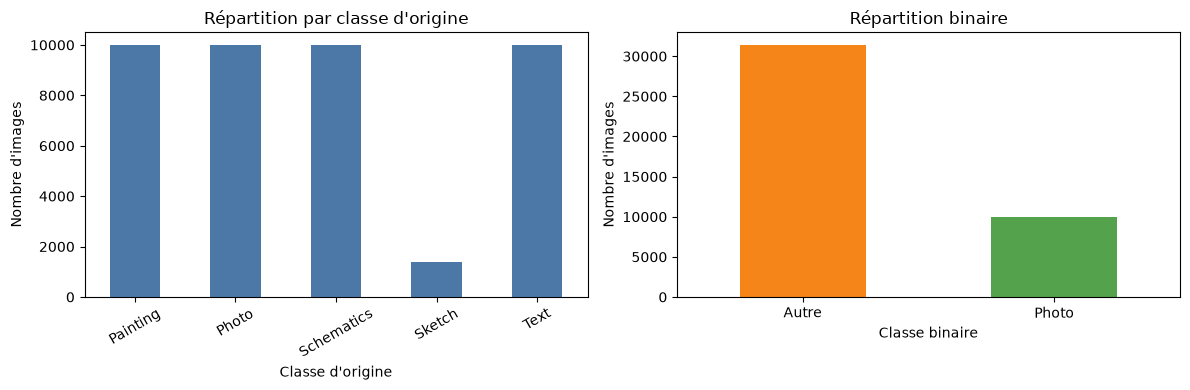

Une prédiction constante Autre donnerait une accuracy de 75.9%


In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["source_class"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="#4C78A8", title="Répartition par classe d'origine"
)
axes[0].set_xlabel("Classe d'origine")
axes[0].set_ylabel("Nombre d'images")
axes[0].tick_params(axis="x", rotation=30)

df["label"].map({0: "Autre", 1: "Photo"}).value_counts().plot(
    kind="bar", ax=axes[1], color=["#F58518", "#54A24B"], title="Répartition binaire"
)
axes[1].set_xlabel("Classe binaire")
axes[1].set_ylabel("Nombre d'images")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print(
    "Une prédiction constante Autre donnerait une accuracy de",
    f"{(df['label'] == 0).mean():.1%}",
)


## 3. Exploration visuelle

Cette étape permet de vérifier que les labels correspondent bien aux images et d’identifier les difficultés possibles avant l’entraînement.

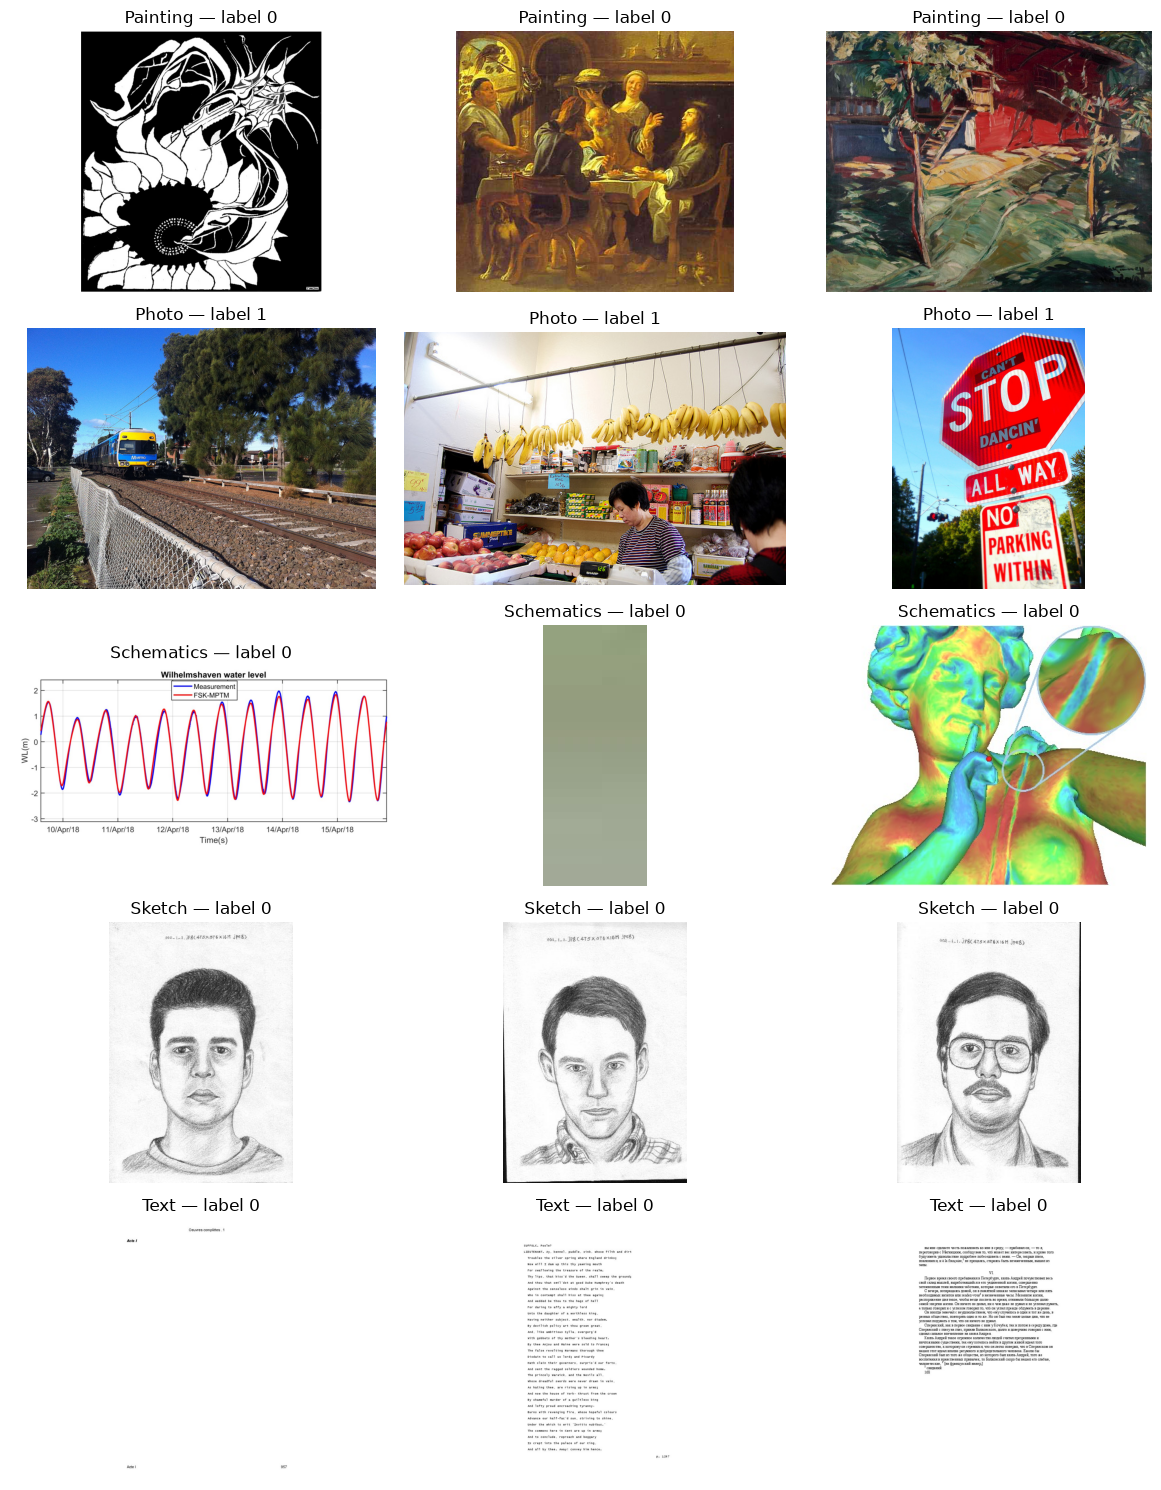

In [63]:
def show_examples(dataframe, samples_per_class=3):
    selected = (
        dataframe.groupby("source_class", group_keys=False)
        .head(samples_per_class)
        .reset_index(drop=True)
    )

    fig, axes = plt.subplots(
        len(SOURCE_CLASSES),
        samples_per_class,
        figsize=(4 * samples_per_class, 3 * len(SOURCE_CLASSES)),
        squeeze=False,
    )

    for row, source_class in enumerate(SOURCE_CLASSES):
        class_rows = selected[selected["source_class"] == source_class]
        for col in range(samples_per_class):
            ax = axes[row, col]
            if col < len(class_rows):
                path = class_rows.iloc[col]["path"]
                with Image.open(path) as image:
                    ax.imshow(image.convert("RGB"))
                ax.set_title(f"{source_class} — label {int(source_class == 'Photo')}")
            ax.axis("off")

    plt.tight_layout()
    plt.show()

show_examples(df)


### Première observation

Les photos et les peintures peuvent partager des textures, des couleurs et des compositions proches. La peinture constitue donc une classe importante à analyser séparément après l’évaluation.

Les schémas, les dessins et les textes scannés peuvent être plus faciles à distinguer, mais cette hypothèse doit être vérifiée avec des statistiques et non seulement avec quelques exemples visuels.

## 4. Séparation entraînement / validation / test

Nous réalisons une séparation stratifiée selon la classe d’origine. Cela garantit que les cinq catégories restent représentées dans les trois ensembles.

- 70 % pour l’entraînement ;
- 15 % pour la validation ;
- 15 % pour le test final.

Le test ne sera pas utilisé pour modifier l’architecture, les hyperparamètres ou le seuil de décision.

In [64]:
df_dev, df_test = train_test_split(
    df,
    test_size=0.15,
    stratify=df["source_class"],
    random_state=SEED,
)

df_train, df_val = train_test_split(
    df_dev,
    test_size=0.15 / 0.85,
    stratify=df_dev["source_class"],
    random_state=SEED,
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

train_paths = set(df_train["path"])
val_paths = set(df_val["path"])
test_paths = set(df_test["path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

print("Entraînement :", len(df_train))
print("Validation   :", len(df_val))
print("Test         :", len(df_test))

distribution = pd.DataFrame({
    "entraînement": df_train["source_class"].value_counts(),
    "validation": df_val["source_class"].value_counts(),
    "test": df_test["source_class"].value_counts(),
}).fillna(0).astype(int)

display(distribution.loc[SOURCE_CLASSES])

Entraînement : 28979
Validation   : 6210
Test         : 6210


,entraînement,validation,test
source_class,,,
Painting,7000,1500,1500
Photo,6995,1499,1499
Schematics,7000,1500,1500
Sketch,984,211,211
Text,7000,1500,1500


## 5. Pipeline TensorFlow

Le pipeline reproduit les méthodes du Workshop 2 :

- lecture des fichiers par batch ;
- conversion RGB ;
- redimensionnement en 180 × 180 ;
- normalisation des pixels dans [0, 1] ;
- mélange uniquement pour l’entraînement ;
- prefetch pour améliorer les performances.

La normalisation est intégrée au modèle afin que le même prétraitement soit utilisé pendant l’entraînement et lors d’une future prédiction.

In [ ]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image.set_shape([*IMAGE_SIZE, 3])
    image = tf.cast(image, tf.float32)     
    return image, tf.cast(label, tf.float32)


def make_dataset(dataframe, training=False):
    paths = dataframe["cache_path"].to_numpy()
    labels = dataframe["label"].to_numpy(dtype=np.float32)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset


train_ds = make_dataset(df_train, training=True)
train_eval_ds = make_dataset(df_train, training=False)
val_ds = make_dataset(df_val)
test_ds = make_dataset(df_test)

sample_images, sample_labels = next(iter(train_eval_ds))
print("Forme d'un batch d'images :", sample_images.shape)
print("Forme d'un batch de labels :", sample_labels.shape)
print("Intervalle des pixels :", float(tf.reduce_min(sample_images)), "à", float(tf.reduce_max(sample_images)))

Forme d'un batch d'images : (32, 180, 180, 3)
Forme d'un batch de labels : (32,)
Intervalle des pixels : 0.0 à 255.0


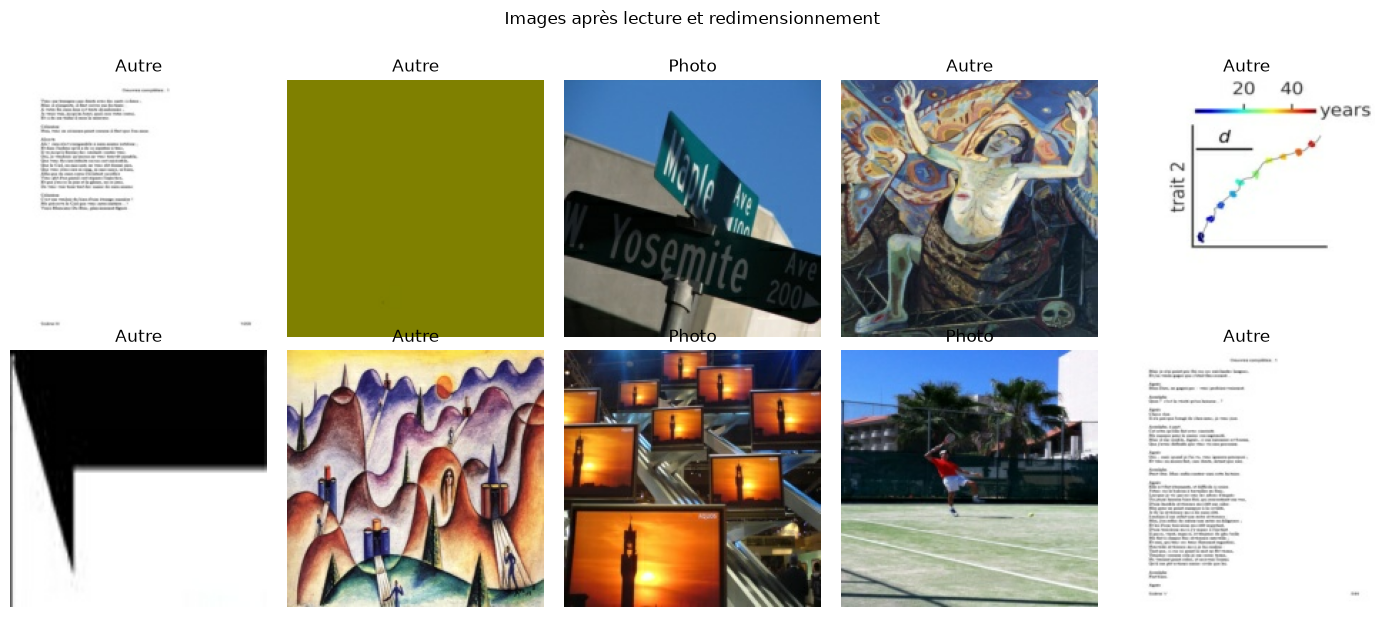

In [66]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for image, label, ax in zip(sample_images[:10], sample_labels[:10], axes.ravel()):
    ax.imshow(image.numpy().astype("uint8"))
    ax.set_title("Photo" if int(label.numpy()) == 1 else "Autre")
    ax.axis("off")

plt.suptitle("Images après lecture et redimensionnement", y=1.02)
plt.tight_layout()
plt.show()

## 6. Poids des classes

La classe Photo est minoritaire. Nous calculons donc les poids uniquement sur l’ensemble d’entraînement.

Ces poids empêchent le modèle de privilégier trop facilement la classe Autre et rendent l’apprentissage plus sensible aux erreurs sur les photos.

In [67]:
classes = np.array([0, 1])
class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=df_train["label"].to_numpy(),
)
CLASS_WEIGHTS = dict(zip(classes, class_weights_values))

print("Poids des classes :", CLASS_WEIGHTS)
display(
    pd.DataFrame({
        "label": [0, 1],
        "classe": ["Autre", "Photo"],
        "poids": class_weights_values,
    })
)

Poids des classes : {np.int64(0): np.float64(0.6590929767103348), np.int64(1): np.float64(2.071408148677627)}


,label,classe,poids
0,0,Autre,0.659093
1,1,Photo,2.071408


## 7. Construction du CNN

Le modèle reprend l’architecture étudiée dans le Workshop 2 :

- les convolutions apprennent des motifs visuels locaux ;
- le pooling réduit progressivement la représentation spatiale ;
- les couches denses réalisent la décision finale ;
- le dropout limite le surapprentissage ;
- la dernière couche produit une probabilité d’appartenance à Photo.

Nous utiliserons deux variantes :

1. un modèle de référence sans augmentation et sans dropout ;
2. un modèle régularisé avec dropout et augmentation légère.

In [ ]:
AUGMENTATION_ENRICHIE = False   # False = Flip, Rotation et Zoom seul ; True = + défauts de numérisation


def build_cnn(name, regularized=False):
    model_layers = [layers.Input(shape=(*IMAGE_SIZE, 3), name="image")]

    if regularized:
        # Augmentation du Workshop 2, placée avant Rescaling comme dans le workshop
        augmentation_layers = [
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.1),
            layers.RandomZoom(0.1),
        ]
        if AUGMENTATION_ENRICHIE:
            # Défauts typiques de la numérisation chez TouNum
            augmentation_layers += [
                layers.RandomTranslation(0.1, 0.1),   # cadrage du scan
                layers.RandomBrightness(0.1),          # exposition (pixels en [0, 255])
                layers.RandomContrast(0.1),            # contraste
            ]
        model_layers.append(keras.Sequential(augmentation_layers, name="augmentation"))

    model_layers.append(layers.Rescaling(1.0 / 255.0, name="normalisation"))

    if regularized and AUGMENTATION_ENRICHIE:
        # Bruit de numérisation, ajouté après normalisation (écart-type de 2 % de l'échelle)
        model_layers.append(layers.GaussianNoise(0.02, name="bruit_numerisation"))

    model_layers.extend([
        layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv_1"),
        layers.MaxPooling2D(name="pool_1"),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv_2"),
        layers.MaxPooling2D(name="pool_2"),
        layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv_3"),
        layers.MaxPooling2D(name="pool_3"),
    ])

    if regularized:
        model_layers.append(layers.Dropout(0.2, name="dropout_conv"))   # valeur du Workshop 2

    model_layers.extend([
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="dense"),
    ])

    if regularized:
        model_layers.append(layers.Dropout(0.25, name="dropout_dense"))

    # float32 en sortie : sigmoïde et perte stables avec la précision mixte
    model_layers.append(
        layers.Dense(1, activation="sigmoid", dtype="float32", name="probability_photo")
    )

    model = keras.Sequential(model_layers, name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=3e-4,
            clipnorm=1.0,
        ),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )
    return model


reference_model = build_cnn("cnn_reference", regularized=False)
regularized_model = build_cnn("cnn_regularized", regularized=True)

reference_model.summary()
regularized_model.summary()

Model: "cnn_reference"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalisation (Rescaling)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probability_photo (Dense)       │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,023,361 (30.61 MB)

 Trainable params: 8,023,361 (30.61 MB)

 Non-trainable params: 0 (0.00 B)

Model: "cnn_regularized"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisation (Rescaling)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_conv (Dropout)          │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probability_photo (Dense)       │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,023,361 (30.61 MB)

 Trainable params: 8,023,361 (30.61 MB)

 Non-trainable params: 0 (0.00 B)

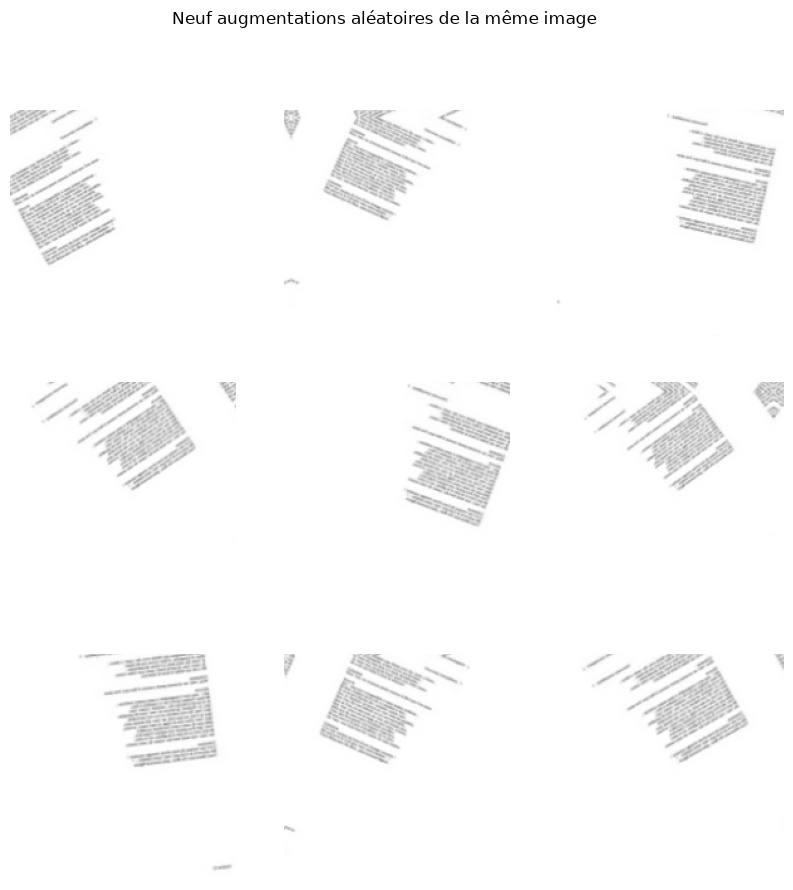

In [69]:
augmentation = regularized_model.get_layer("augmentation")
images, _ = next(iter(train_eval_ds))

plt.figure(figsize=(10, 10))
for i in range(9):
    augmented = augmentation(images[:1], training=True)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented[0].numpy().astype("uint8"))
    plt.axis("off")
plt.suptitle("Neuf augmentations aléatoires de la même image")
plt.show()

## 8. Entraînement

L'entraînement est volontairement réalisé avec de l'EarlyStopping pour le modèle de référence et régularisé.

ReduceLROnPlateau peut réduire le taux d'apprentissage lorsque la validation
stagne, mais il ne peut pas interrompre l'entraînement.

Les deux modèles sont comparés sur la validation. Le test reste fermé pendant cette étape.

In [70]:
def train_model(model, train_data, validation_data, model_name, min_epochs=0):
    callbacks = [
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_delta=0.001,
            min_lr=1e-6,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            min_delta=0.001,
            restore_best_weights=True,
            start_from_epoch=min_epochs,
        ),
    ]

    start = perf_counter()
    with tf.device(TRAINING_DEVICE):
        history = model.fit(
            train_data,
            validation_data=validation_data,
            epochs=MAX_EPOCHS,
            shuffle=False,
            class_weight=CLASS_WEIGHTS,
            callbacks=callbacks,
            verbose=1,
        )
    elapsed = perf_counter() - start

    print(f"{model_name} entraîné en {elapsed:.1f} secondes")
    return history


reference_history = train_model(
    reference_model, train_ds, val_ds, "CNN de référence"
)

regularized_history = train_model(
    regularized_model, train_ds, val_ds, "CNN régularisé"
)

Epoch 1/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 35s 36ms/step - accuracy: 0.7740 - auc: 0.8930 - loss: 0.3926 - precision: 0.5186 - recall: 0.8895 - val_accuracy: 0.8412 - val_auc: 0.9358 - val_loss: 0.3180 - val_precision: 0.6170 - val_recall: 0.9026 - learning_rate: 3.0000e-04
Epoch 2/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 31s 34ms/step - accuracy: 0.8433 - auc: 0.9359 - loss: 0.3129 - precision: 0.6203 - recall: 0.9041 - val_accuracy: 0.8771 - val_auc: 0.9493 - val_loss: 0.2845 - val_precision: 0.6917 - val_recall: 0.8859 - learning_rate: 3.0000e-04
Epoch 3/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step - accuracy: 0.8803 - auc: 0.9576 - loss: 0.2567 - precision: 0.6901 - recall: 0.9148 - val_accuracy: 0.8836 - val_auc: 0.9642 - val_loss: 0.2544 - val_precision: 0.6934 - val_recall: 0.9280 - learning_rate: 3.0000e-04
Epoch 4/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 30s 33ms/step - accuracy: 0.9038 - auc: 0.9699 - loss: 0.2169 - precision: 0.7394 - recall: 0.9289 - val_accuracy: 0.9072 - val_auc: 0.9646 - va

E0000 00:00:1791210791.918744   88243 meta_optimizer.cc:996] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape incnn_regularized/dropout_conv/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


906/906 ━━━━━━━━━━━━━━━━━━━━ 43s 46ms/step - accuracy: 0.7536 - auc: 0.8712 - loss: 0.4237 - precision: 0.4942 - recall: 0.8896 - val_accuracy: 0.7910 - val_auc: 0.9044 - val_loss: 0.3532 - val_precision: 0.5423 - val_recall: 0.8592 - learning_rate: 3.0000e-04
Epoch 2/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 40s 44ms/step - accuracy: 0.7889 - auc: 0.9046 - loss: 0.3734 - precision: 0.5369 - recall: 0.9115 - val_accuracy: 0.8312 - val_auc: 0.9268 - val_loss: 0.3113 - val_precision: 0.6063 - val_recall: 0.8579 - learning_rate: 3.0000e-04
Epoch 3/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 40s 44ms/step - accuracy: 0.8223 - auc: 0.9245 - loss: 0.3363 - precision: 0.5848 - recall: 0.9096 - val_accuracy: 0.8601 - val_auc: 0.9424 - val_loss: 0.2869 - val_precision: 0.6546 - val_recall: 0.8899 - learning_rate: 3.0000e-04
Epoch 4/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 40s 44ms/step - accuracy: 0.8442 - auc: 0.9371 - loss: 0.3099 - precision: 0.6208 - recall: 0.9107 - val_accuracy: 0.8366 - val_auc: 0.9561 - val_loss: 0.3

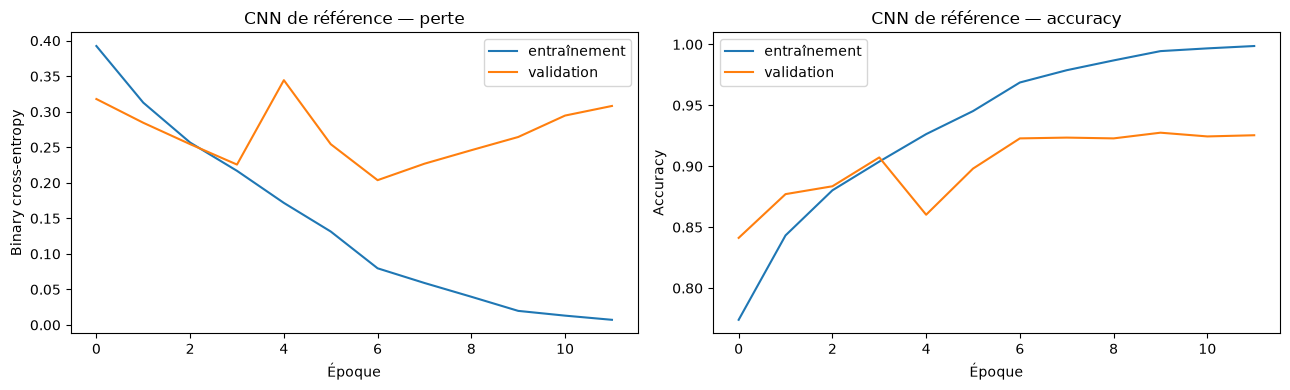

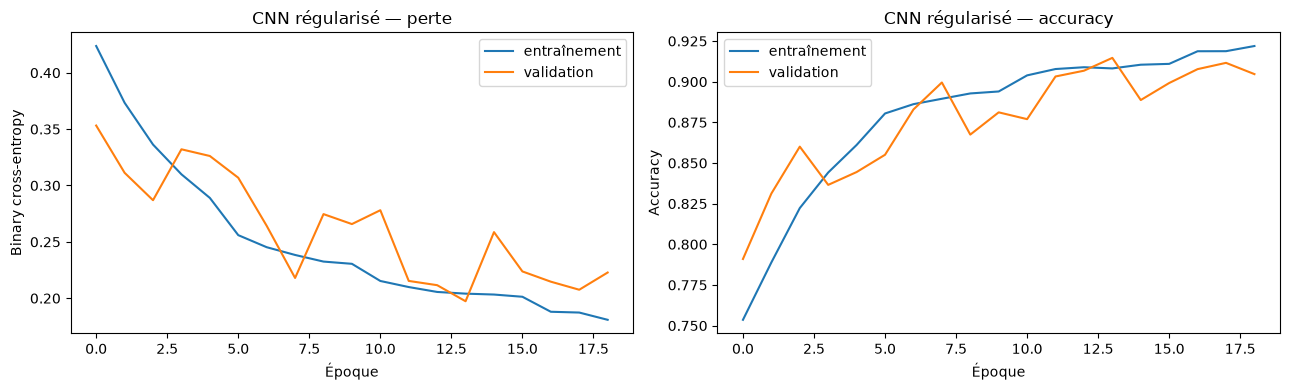

In [71]:
def plot_history(history, title):
    history_df = pd.DataFrame(history.history)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(history_df["loss"], label="entraînement")
    axes[0].plot(history_df["val_loss"], label="validation")
    axes[0].set_title(f"{title} — perte")
    axes[0].set_xlabel("Époque")
    axes[0].set_ylabel("Binary cross-entropy")
    axes[0].legend()

    axes[1].plot(history_df["accuracy"], label="entraînement")
    axes[1].plot(history_df["val_accuracy"], label="validation")
    axes[1].set_title(f"{title} — accuracy")
    axes[1].set_xlabel("Époque")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


plot_history(reference_history, "CNN de référence")
plot_history(regularized_history, "CNN régularisé")

### Analyse des courbes : CNN de référence et CNN régularisé

**CNN de référence : surapprentissage (variance élevée).** La perte d'entraînement descend presque à 0 et l'accuracy d'entraînement atteint 100 %, alors que la perte de validation atteint son minimum (≈ 0,20) à la 7e époque puis remonte. Le modèle mémorise les images d'entraînement au lieu d'apprendre à généraliser. L'early stopping a restauré les poids de la 7e époque, la meilleure sur la validation.

**CNN régularisé : variance maîtrisée, mais biais limitant.** Grâce à l'augmentation de données et au dropout, les deux courbes restent proches et la perte de validation s'améliore jusqu'à la 14e époque (≈ 0,197). Le surapprentissage a disparu. En revanche, la perte d'entraînement ne descend plus sous 0,18 : le modèle n'arrive pas à mieux apprendre, car il manque de capacité pour extraire des caractéristiques assez fines.

| | CNN de référence | CNN régularisé |
|---|---|---|
| Meilleure perte de validation | ≈ 0,20 | ≈ 0,197 |
| Écart entraînement / validation | très important | faible |
| Diagnostic | variance élevée | biais limitant |

Le CNN à 4 blocs vise à réduire ce biais sans faire réapparaître la variance.

,modèle,meilleure époque,meilleure val_loss,début du plateau,min_delta,patience
0,CNN de référence,7,0.203751,8,0.001,3
1,CNN régularisé,14,0.197317,15,0.001,3


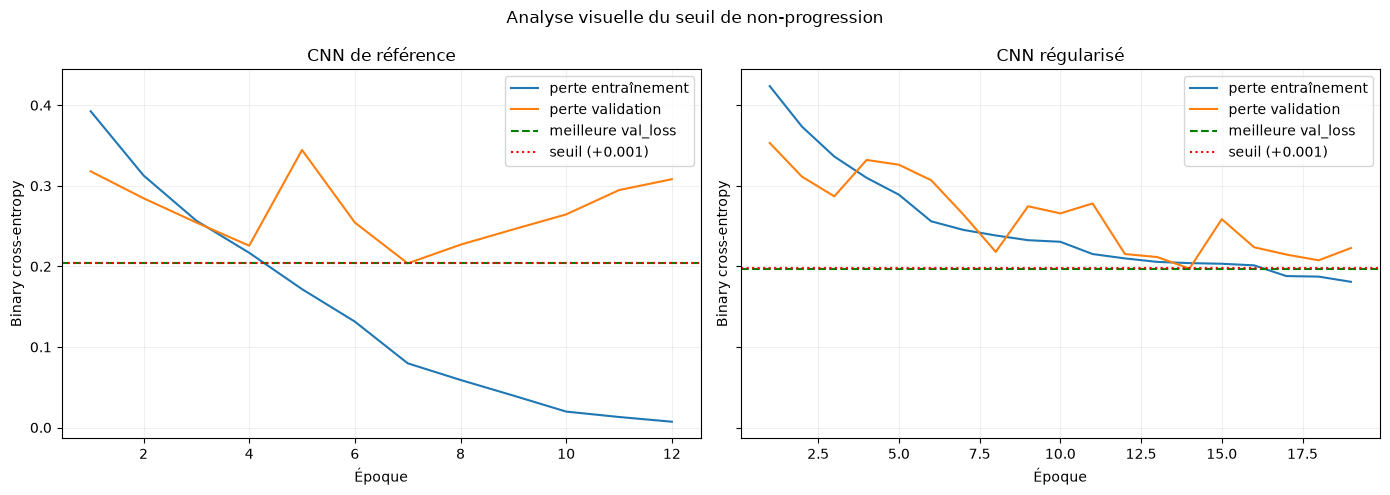

In [ ]:
# Analyse a posteriori de la non-progression de la validation.
NON_PROGRESS_DELTA = 0.001
NON_PROGRESS_PATIENCE = 3

def analyze_non_progress(history, model_name, min_delta=NON_PROGRESS_DELTA, patience=NON_PROGRESS_PATIENCE):
    val_loss = np.asarray(history.history["val_loss"], dtype=float)
    epochs = np.arange(1, len(val_loss) + 1)
    best_index = int(np.argmin(val_loss))
    best_epoch = int(epochs[best_index])
    best_value = float(val_loss[best_index])

    plateau_epoch = None
    for index in range(best_index + 1, len(val_loss) - patience + 1):
        following_values = val_loss[index:index + patience]
        previous_value = val_loss[index - 1]
        if np.all(following_values >= previous_value - min_delta):
            plateau_epoch = int(epochs[index])
            break

    plateau_text = (
        f"plateau détecté à partir de l'époque {plateau_epoch}"
        if plateau_epoch is not None
        else "aucun plateau détecté avec ces paramètres"
    )

    return {
        "modèle": model_name,
        "meilleure époque": best_epoch,
        "meilleure val_loss": best_value,
        "début du plateau": plateau_epoch,
        "min_delta": min_delta,
        "patience": patience,
    }

plateau_results = pd.DataFrame([
    analyze_non_progress(reference_history, "CNN de référence"),
    analyze_non_progress(regularized_history, "CNN régularisé"),
])
display(plateau_results)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
histories = [
    (reference_history, "CNN de référence"),
    (regularized_history, "CNN régularisé"),
]

for ax, (history, model_name) in zip(axes, histories):
    epochs = np.arange(1, len(history.history["val_loss"]) + 1)
    train_loss = np.asarray(history.history["loss"], dtype=float)
    val_loss = np.asarray(history.history["val_loss"], dtype=float)
    best_loss = float(np.min(val_loss))
    non_progress_threshold = best_loss + NON_PROGRESS_DELTA

    ax.plot(epochs, train_loss, label="perte entraînement")
    ax.plot(epochs, val_loss, label="perte validation")
    ax.axhline(best_loss, color="green", linestyle="--", label="meilleure val_loss")
    ax.axhline(
        non_progress_threshold,
        color="red",
        linestyle=":",
        label=f"seuil (+{NON_PROGRESS_DELTA})",
    )
    ax.set_title(model_name)
    ax.set_xlabel("Époque")
    ax.set_ylabel("Binary cross-entropy")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle("Analyse visuelle du seuil de non-progression")
plt.tight_layout()
plt.show()

### Expérience : un CNN à 4 blocs convolutifs

Dans les deux modèles précédents, 98,8 % des paramètres se trouvent dans la couche dense qui suit le `Flatten` (7,9 millions), contre seulement 93 248 dans les convolutions. Le réseau peut donc mémoriser les images d'entraînement (variance), tout en manquant de capacité pour extraire des caractéristiques visuelles fines (biais).

Nous ajoutons un 4e bloc convolutif (256 filtres + max pooling). D'après le SAM CNN, les couches profondes apprennent des caractéristiques de plus haut niveau. Le pooling supplémentaire réduit la carte de 22 × 22 à 11 × 11, ce qui divise par deux la taille du `Flatten` et de la couche dense. Le modèle garde la régularisation du Workshop 2.

In [73]:
def build_cnn_4blocs(name="cnn_4blocs"):
    model = keras.Sequential([
        layers.Input(shape=(*IMAGE_SIZE, 3), name="image"),
        keras.Sequential(
            [
                layers.RandomFlip("horizontal"),
                layers.RandomRotation(0.1),
                layers.RandomZoom(0.1),
            ],
            name="augmentation",
        ),
        layers.Rescaling(1.0 / 255.0, name="normalisation"),

        layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv_1"),
        layers.MaxPooling2D(name="pool_1"),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv_2"),
        layers.MaxPooling2D(name="pool_2"),
        layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv_3"),
        layers.MaxPooling2D(name="pool_3"),
        layers.Conv2D(256, (3, 3), padding="same", activation="relu", name="conv_4"),
        layers.MaxPooling2D(name="pool_4"),
        layers.Dropout(0.2, name="dropout_conv"),

        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="dense"),
        layers.Dropout(0.25, name="dropout_dense"),
        layers.Dense(1, activation="sigmoid", dtype="float32", name="probability_photo"),
    ], name=name)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=3e-4, clipnorm=1.0),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )
    return model


cnn_4blocs = build_cnn_4blocs()
cnn_4blocs.summary()

Model: "cnn_4blocs"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisation (Rescaling)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 22, 22, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_4 (MaxPooling2D)           │ (None, 11, 11, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_conv (Dropout)          │ (None, 11, 11, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probability_photo (Dense)       │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353,601 (16.61 MB)

 Trainable params: 4,353,601 (16.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40


E0000 00:00:1791211559.264479   88243 meta_optimizer.cc:996] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape incnn_4blocs/dropout_conv/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


906/906 ━━━━━━━━━━━━━━━━━━━━ 45s 48ms/step - accuracy: 0.7584 - auc: 0.8760 - loss: 0.4177 - precision: 0.4998 - recall: 0.8869 - val_accuracy: 0.8016 - val_auc: 0.9182 - val_loss: 0.3325 - val_precision: 0.5548 - val_recall: 0.9019 - learning_rate: 3.0000e-04
Epoch 2/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 42s 46ms/step - accuracy: 0.8132 - auc: 0.9177 - loss: 0.3487 - precision: 0.5710 - recall: 0.9089 - val_accuracy: 0.8280 - val_auc: 0.9391 - val_loss: 0.3384 - val_precision: 0.5904 - val_recall: 0.9386 - learning_rate: 3.0000e-04
Epoch 3/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 42s 46ms/step - accuracy: 0.8292 - auc: 0.9293 - loss: 0.3231 - precision: 0.5954 - recall: 0.9119 - val_accuracy: 0.8638 - val_auc: 0.9452 - val_loss: 0.2933 - val_precision: 0.6566 - val_recall: 0.9133 - learning_rate: 3.0000e-04
Epoch 4/40
906/906 ━━━━━━━━━━━━━━━━━━━━ 42s 46ms/step - accuracy: 0.8459 - auc: 0.9403 - loss: 0.2992 - precision: 0.6225 - recall: 0.9191 - val_accuracy: 0.8739 - val_auc: 0.9520 - val_loss: 0.2

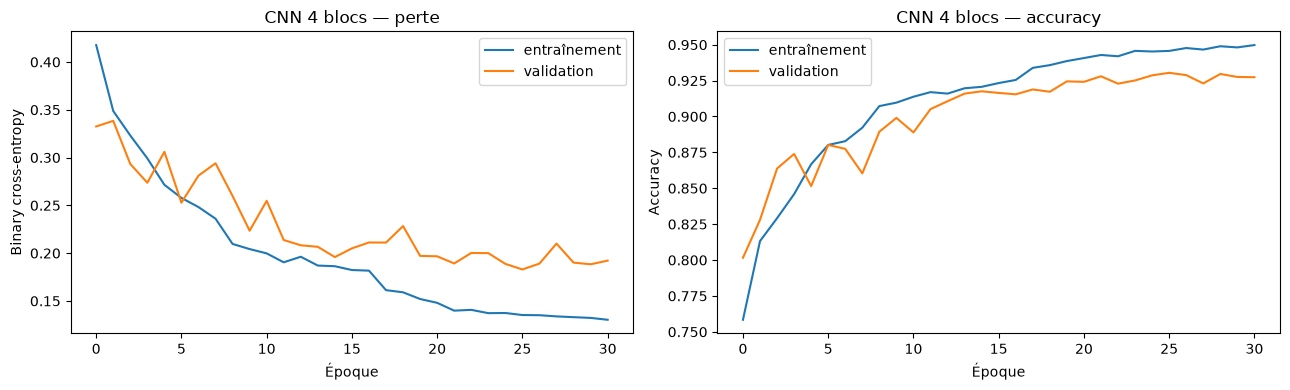

,modèle,meilleure époque,meilleure val_loss,début du plateau,min_delta,patience
0,CNN 4 blocs,26,0.182952,27,0.001,3


In [74]:
history_4blocs = train_model(cnn_4blocs, train_ds, val_ds, "CNN 4 blocs", min_epochs=15)
plot_history(history_4blocs, "CNN 4 blocs")
display(pd.DataFrame([analyze_non_progress(history_4blocs, "CNN 4 blocs")]))

### Analyse des courbes : CNN 4 blocs

**Le biais a diminué.** La perte d'entraînement descend jusqu'à ≈ 0,13, contre 0,18 pour le CNN régularisé : grâce au 4e bloc convolutif, le modèle apprend des caractéristiques plus fines.

**La variance reste maîtrisée.** Les deux courbes restent proches pendant la majeure partie de l'entraînement. Un léger écart apparaît après la 20e époque (la perte d'entraînement continue de baisser alors que la validation se stabilise autour de 0,19) : c'est le début d'un surapprentissage, que l'early stopping a arrêté.

**C'est le meilleur des trois modèles**, avec une perte de validation minimale de **0,183** à la 26e époque et une accuracy de validation d'environ 93 %, alors qu'il compte deux fois moins de paramètres.

| | CNN de référence | CNN régularisé | CNN 4 blocs |
|---|---|---|---|
| Meilleure perte de validation | ≈ 0,20 | ≈ 0,197 | **0,183** |
| Diagnostic | variance élevée | biais limitant | **meilleur compromis** |

In [91]:
val_loss = np.asarray(history_4blocs.history["val_loss"])

best_global = int(np.argmin(val_loss))
best_monitored = 20 + int(np.argmin(val_loss[20:]))

print(f"Époques effectuées : {len(val_loss)}")
print(f"Meilleure val_loss sur toutes les époques : {val_loss[best_global]:.4f} (époque {best_global + 1})")
print(f"Meilleure val_loss à partir de l'époque 16 (modèle conservé) : {val_loss[best_monitored]:.4f} (époque {best_monitored + 1})")

Époques effectuées : 31
Meilleure val_loss sur toutes les époques : 0.1830 (époque 26)
Meilleure val_loss à partir de l'époque 16 (modèle conservé) : 0.1830 (époque 26)


## 9. Fonctions d’évaluation

L’accuracy, la précision et le rappel sont calculés avec un seuil de décision explicite.

Nous ajoutons :

- le F1-score macro ;
- la balanced accuracy ;
- la ROC-AUC ;
- la PR-AUC ;
- la matrice de confusion.

Le F1 macro donne le même poids aux deux classes, ce qui est adapté au déséquilibre observé.

In [76]:
def predict_probabilities(model, dataset):
    probabilities = model.predict(dataset, verbose=0).reshape(-1)
    return probabilities


def compute_metrics(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "precision_photo": precision_score(y_true, predictions, pos_label=1, zero_division=0),
        "recall_photo": recall_score(y_true, predictions, pos_label=1, zero_division=0),
        "f1_macro": f1_score(y_true, predictions, average="macro"),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
    }


def evaluate_model(model, dataframe, dataset, threshold=0.5):
    probabilities = predict_probabilities(model, dataset)
    metrics = compute_metrics(
        dataframe["label"].to_numpy(),
        probabilities,
        threshold=threshold,
    )
    return metrics, probabilities


y_val = df_val["label"].to_numpy()

reference_val_metrics, reference_val_probabilities = evaluate_model(
    reference_model, df_val, val_ds
)
regularized_val_metrics, regularized_val_probabilities = evaluate_model(
    regularized_model, df_val, val_ds
)
cnn_4blocs_val_metrics, cnn_4blocs_val_probabilities = evaluate_model(
    cnn_4blocs, df_val, val_ds
)

comparison = pd.DataFrame([
    {"modèle": "CNN référence", **reference_val_metrics},
    {"modèle": "CNN régularisé", **regularized_val_metrics},
    {"modèle": "CNN 4 blocs", **cnn_4blocs_val_metrics},
]).set_index("modèle")

display(comparison.round(4))

,accuracy,balanced_accuracy,precision_photo,recall_photo,f1_macro,roc_auc,pr_auc
modèle,,,,,,,
CNN référence,0.9229,0.9007,0.8286,0.8579,0.8959,0.9711,0.9086
CNN régularisé,0.9147,0.9183,0.7684,0.9253,0.8907,0.9759,0.9260
CNN 4 blocs,0.9304,0.9303,0.8100,0.9300,0.9094,0.9814,0.9468


## 10. Choix du modèle et du seuil

Le modèle est choisi sur la validation avec le meilleur F1 macro.

Le seuil peut ensuite être ajusté sur cette même validation. Cette étape est utile lorsque le coût des faux négatifs et des faux positifs n’est pas identique.

Aucune information du test n’est utilisée pour cette décision.

Modèle choisi : CNN 4 blocs
Seuil choisi sur la validation : 0.78
F1 macro obtenu : 0.9229137776327596


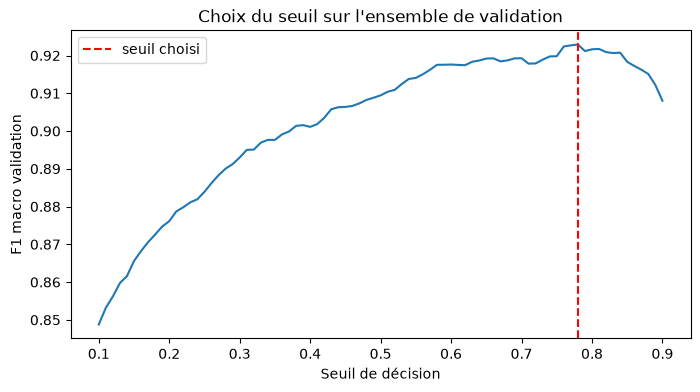

In [77]:
models = {
    "CNN référence": reference_model,
    "CNN régularisé": regularized_model,
    "CNN 4 blocs": cnn_4blocs,
}

validation_results = {
    "CNN référence": reference_val_metrics,
    "CNN régularisé": regularized_val_metrics,
    "CNN 4 blocs": cnn_4blocs_val_metrics,
}

validation_probabilities = {
    "CNN référence": reference_val_probabilities,
    "CNN régularisé": regularized_val_probabilities,
    "CNN 4 blocs": cnn_4blocs_val_probabilities,
}

best_model_name = max(
    validation_results,
    key=lambda name: validation_results[name]["f1_macro"],
)
best_model = models[best_model_name]
best_val_probabilities = validation_probabilities[best_model_name]

thresholds = np.linspace(0.10, 0.90, 81)
threshold_scores = [
    f1_score(
        y_val,
        (best_val_probabilities >= threshold).astype(int),
        average="macro",
    )
    for threshold in thresholds
]

best_threshold = float(thresholds[int(np.argmax(threshold_scores))])
DECISION_THRESHOLD = best_threshold

print("Modèle choisi :", best_model_name)
print("Seuil choisi sur la validation :", DECISION_THRESHOLD)
print("F1 macro obtenu :", max(threshold_scores))

plt.figure(figsize=(8, 4))
plt.plot(thresholds, threshold_scores)
plt.axvline(DECISION_THRESHOLD, color="red", linestyle="--", label="seuil choisi")
plt.xlabel("Seuil de décision")
plt.ylabel("F1 macro validation")
plt.title("Choix du seuil sur l'ensemble de validation")
plt.legend()
plt.show()

## 11. Évaluation détaillée sur la validation

Avant d’utiliser le test, nous analysons le comportement du modèle choisi sur la validation.

Cette étape permet de vérifier que le score global ne masque pas une mauvaise détection des photos ou une classe particulièrement difficile.

Validation


,accuracy,balanced_accuracy,precision_photo,recall_photo,f1_macro,roc_auc,pr_auc
0,0.9436,0.9221,0.8853,0.8806,0.9229,0.9814,0.9468


              precision    recall  f1-score   support

       Autre     0.9621    0.9637    0.9629      4711
       Photo     0.8853    0.8806    0.8829      1499

    accuracy                         0.9436      6210
   macro avg     0.9237    0.9221    0.9229      6210
weighted avg     0.9435    0.9436    0.9436      6210



,Prédit Autre,Prédit Photo
Réel Autre,4540,171
Réel Photo,179,1320


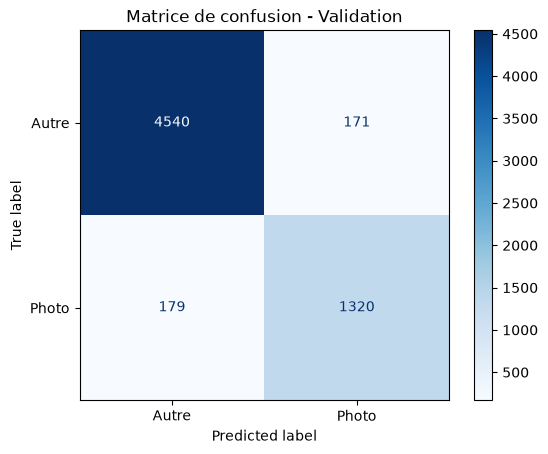

In [92]:
def display_evaluation(model, dataframe, dataset, threshold, title):
    y_true = dataframe["label"].to_numpy()
    probabilities = predict_probabilities(model, dataset)
    predictions = (probabilities >= threshold).astype(int)

    print(title)
    display(pd.DataFrame([
        compute_metrics(y_true, probabilities, threshold)
    ]).round(4))

    print(classification_report(
        y_true,
        predictions,
        target_names=["Autre", "Photo"],
        digits=4,
        zero_division=0,
    ))

    matrix = confusion_matrix(y_true, predictions, labels=[0, 1])
    display(pd.DataFrame(
        matrix,
        index=["Réel Autre", "Réel Photo"],
        columns=["Prédit Autre", "Prédit Photo"],
    ))

    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Autre", "Photo"],
    ).plot(cmap="Blues", values_format="d")
    plt.title(f"Matrice de confusion - {title}")
    plt.show()

    return probabilities, predictions


val_probabilities, val_predictions = display_evaluation(
    best_model,
    df_val,
    val_ds,
    DECISION_THRESHOLD,
    "Validation",
)

## 12. Analyse par classe d’origine

La classe binaire Autre regroupe plusieurs réalités visuelles. Nous mesurons donc le comportement du modèle pour chaque classe d’origine.

Pour les classes non photographiques, le taux prédit comme Photo correspond à un taux de faux positifs.

Cette analyse est particulièrement importante pour Painting, car la consigne identifie la distinction photo/peinture comme une difficulté possible.

In [79]:
def analyze_source_classes(dataframe, probabilities, threshold):
    result = dataframe[["source_class", "label"]].copy()
    result["probability_photo"] = probabilities
    result["prediction"] = (probabilities >= threshold).astype(int)

    rows = []
    for source_class, group in result.groupby("source_class"):
        if source_class == "Photo":
            error_rate = (group["prediction"] == 0).mean()
            interpretation = "faux négatifs"
        else:
            error_rate = (group["prediction"] == 1).mean()
            interpretation = "faux positifs"

        rows.append({
            "classe originale": source_class,
            "nombre": len(group),
            "probabilité Photo moyenne": group["probability_photo"].mean(),
            "taux d'erreur binaire": error_rate,
            "type d'erreur": interpretation,
        })

    return pd.DataFrame(rows).sort_values("classe originale")


source_validation = analyze_source_classes(
    df_val,
    val_probabilities,
    DECISION_THRESHOLD,
)

display(source_validation.round(4))

,classe originale,nombre,probabilité Photo moyenne,taux d'erreur binaire,type d'erreur
0,Painting,1500,0.2170,0.0933,faux positifs
1,Photo,1499,0.9068,0.1194,faux négatifs
2,Schematics,1500,0.0420,0.0207,faux positifs
3,Sketch,211,0.0003,0.0000,faux positifs
4,Text,1500,0.0000,0.0000,faux positifs


,Prédit Autre,Prédit Photo
source_class,,
Painting,1360,140
Photo,179,1320
Schematics,1469,31
Sketch,211,0
Text,1500,0


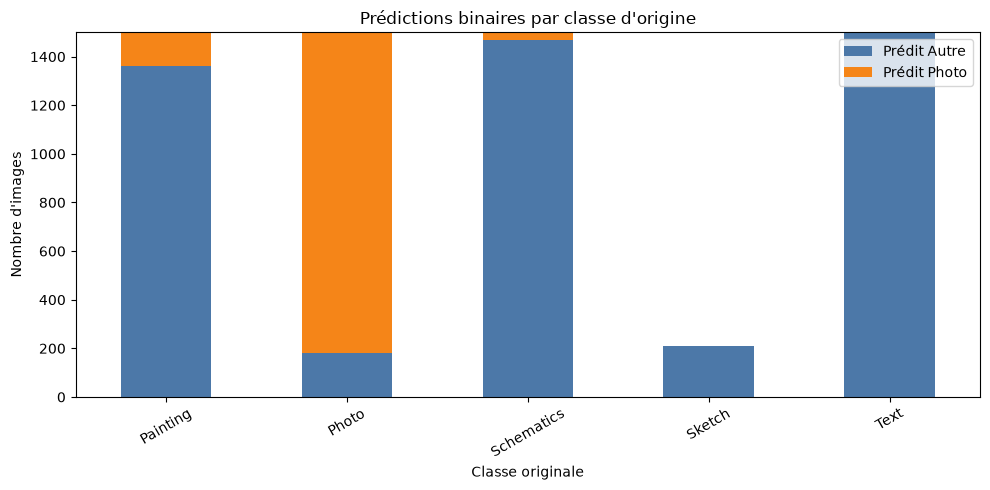

In [80]:
source_matrix = pd.crosstab(
    df_val["source_class"],
    val_predictions,
).reindex(index=SOURCE_CLASSES, columns=[0, 1], fill_value=0)

source_matrix.columns = ["Prédit Autre", "Prédit Photo"]
display(source_matrix)

source_matrix.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=["#4C78A8", "#F58518"],
    title="Prédictions binaires par classe d'origine",
)
plt.xlabel("Classe originale")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 13. Analyse qualitative des erreurs

Les exemples d’erreurs permettent de compléter les métriques numériques.

Nous affichons des faux positifs et des faux négatifs avec leur probabilité prédite.

In [86]:
val_analysis = df_val.copy()
val_analysis["probability_photo"] = val_probabilities
val_analysis["prediction"] = val_predictions
val_analysis["prediction_name"] = val_analysis["prediction"].map({
    0: "Autre",
    1: "Photo",
})

false_positives = val_analysis[
    (val_analysis["label"] == 0) & (val_analysis["prediction"] == 1)
].sort_values("probability_photo", ascending=False)

false_negatives = val_analysis[
    (val_analysis["label"] == 1) & (val_analysis["prediction"] == 0)
].sort_values("probability_photo", ascending=True)


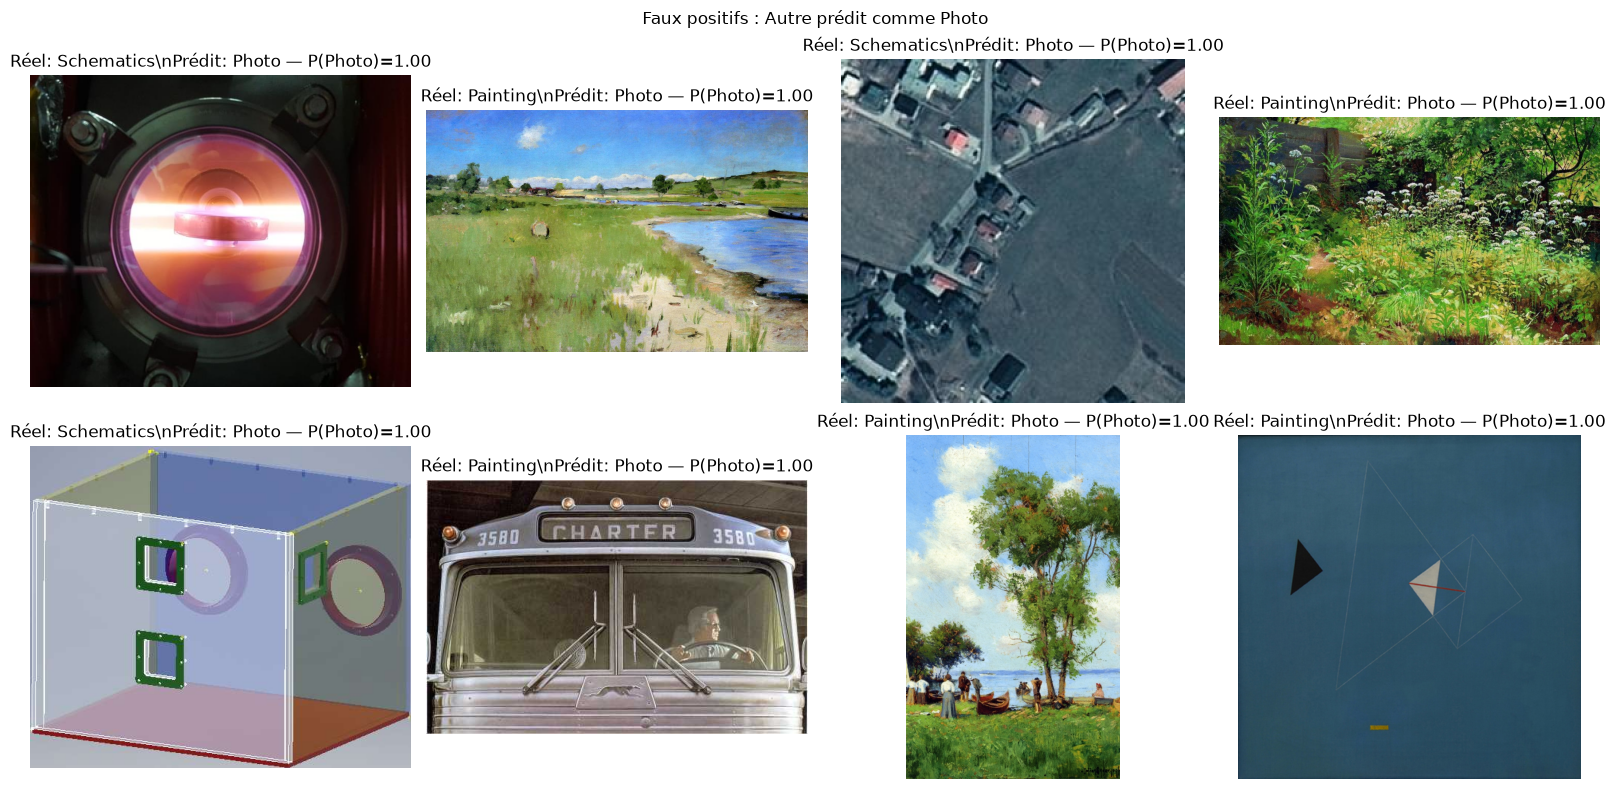

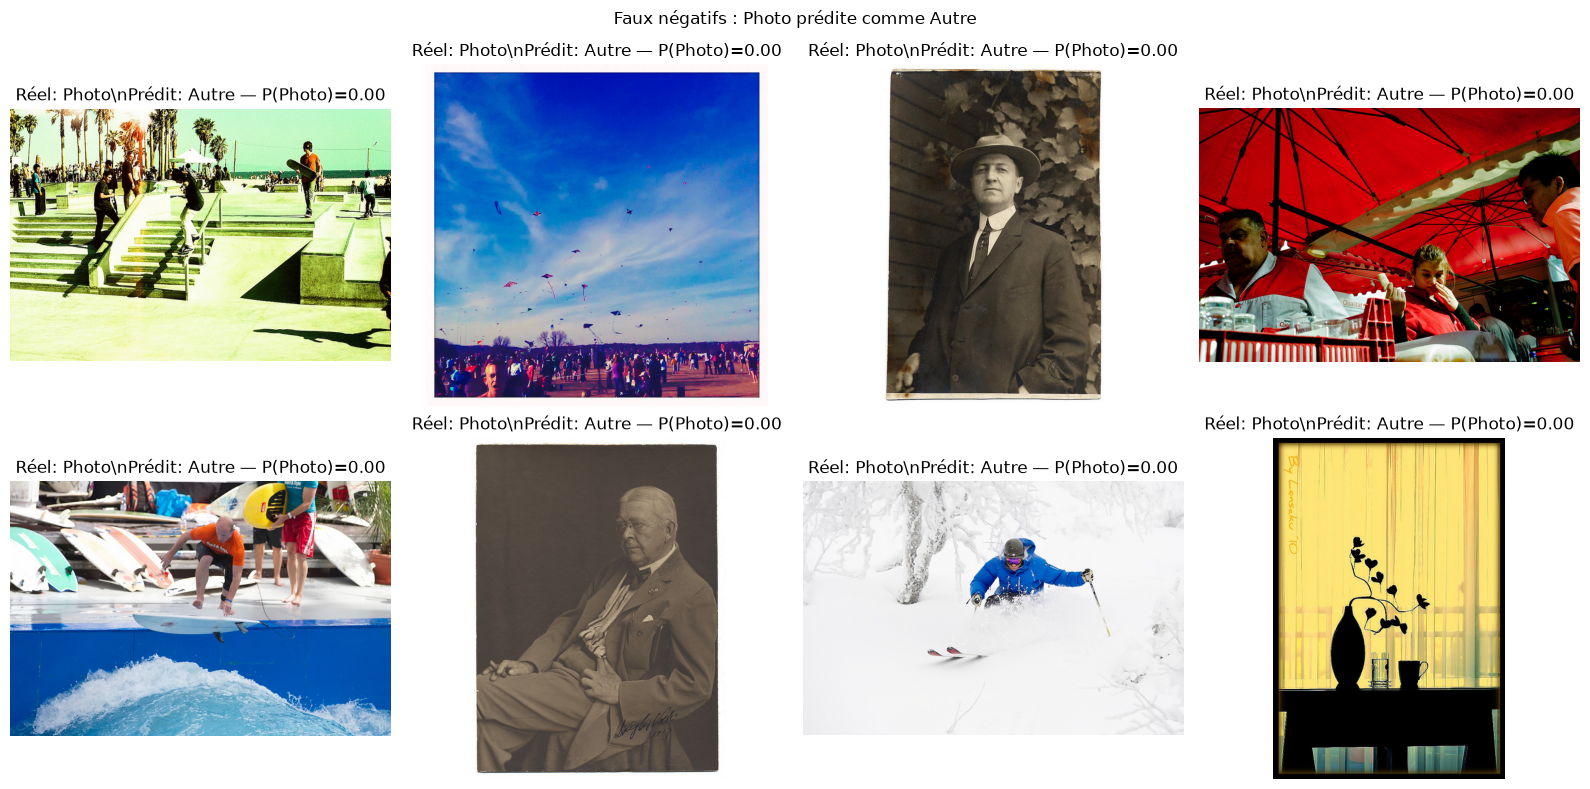

In [87]:
def show_error_examples(dataframe, title, n=8):
    examples = dataframe.head(n)

    if examples.empty:
        print(f"Aucune erreur dans la catégorie : {title}")
        return

    columns = min(4, len(examples))
    rows = int(np.ceil(len(examples) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4 * rows), squeeze=False)

    for ax, (_, row) in zip(axes.ravel(), examples.iterrows()):
        with Image.open(row["path"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(
            f"Réel: {row['source_class']}\\n"
            f"Prédit: {row['prediction_name']} — "
            f"P(Photo)={row['probability_photo']:.2f}"
        )
        ax.axis("off")

    for ax in axes.ravel()[len(examples):]:
        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show_error_examples(false_positives, "Faux positifs : Autre prédit comme Photo")
show_error_examples(false_negatives, "Faux négatifs : Photo prédite comme Autre")

## 14. Évaluation finale sur le test

Le modèle et le seuil étant maintenant figés, nous pouvons évaluer la généralisation sur le test.

Cette cellule ne doit pas être suivie d’une modification du modèle. Si les résultats sont décevants, il faudra recommencer une nouvelle expérience en conservant le test comme ensemble final indépendant.

Test final


,accuracy,balanced_accuracy,precision_photo,recall_photo,f1_macro,roc_auc,pr_auc
0,0.9367,0.9094,0.8782,0.8566,0.9129,0.9783,0.9367


              precision    recall  f1-score   support

       Autre     0.9547    0.9622    0.9585      4711
       Photo     0.8782    0.8566    0.8673      1499

    accuracy                         0.9367      6210
   macro avg     0.9165    0.9094    0.9129      6210
weighted avg     0.9363    0.9367    0.9364      6210



,Prédit Autre,Prédit Photo
Réel Autre,4533,178
Réel Photo,215,1284


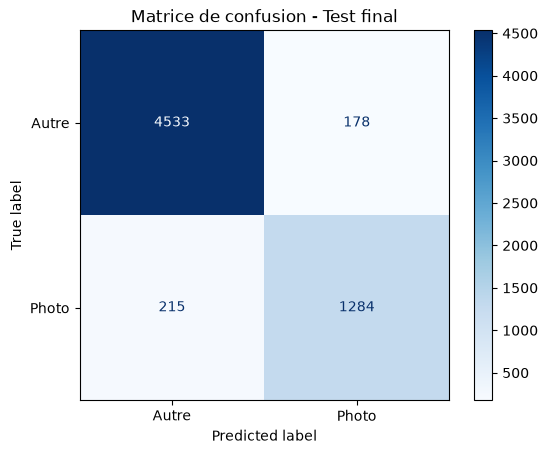

,classe originale,nombre,probabilité Photo moyenne,taux d'erreur binaire,type d'erreur
0,Painting,1500,0.2265,0.0993,faux positifs
1,Photo,1499,0.8946,0.1434,faux négatifs
2,Schematics,1500,0.0375,0.0193,faux positifs
3,Sketch,211,0.0002,0.0000,faux positifs
4,Text,1500,0.0000,0.0000,faux positifs


In [93]:
test_probabilities, test_predictions = display_evaluation(
    best_model,
    df_test,
    test_ds,
    DECISION_THRESHOLD,
    "Test final",
)

test_source_analysis = analyze_source_classes(
    df_test,
    test_probabilities,
    DECISION_THRESHOLD,
)
display(test_source_analysis.round(4))

## 15. Fonction de prédiction sur une nouvelle image

Cette fonction reproduit le prétraitement utilisé pendant l’entraînement. Elle représente le comportement attendu lors de l’intégration dans le workflow TouNum.

In [89]:
def predict_image(path, model=best_model, threshold=DECISION_THRESHOLD):
    path = str(path)

    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False,
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)[tf.newaxis, ...]

    probability = float(model.predict(image, verbose=0)[0, 0])
    prediction = "Photo" if probability >= threshold else "Autre"

    return {
        "chemin": path,
        "prediction": prediction,
        "probabilité Photo": probability,
        "seuil": threshold,
    }


demo_paths = [
    df_test.iloc[index]["path"]
    for index in np.linspace(0, len(df_test) - 1, min(5, len(df_test)), dtype=int)
]


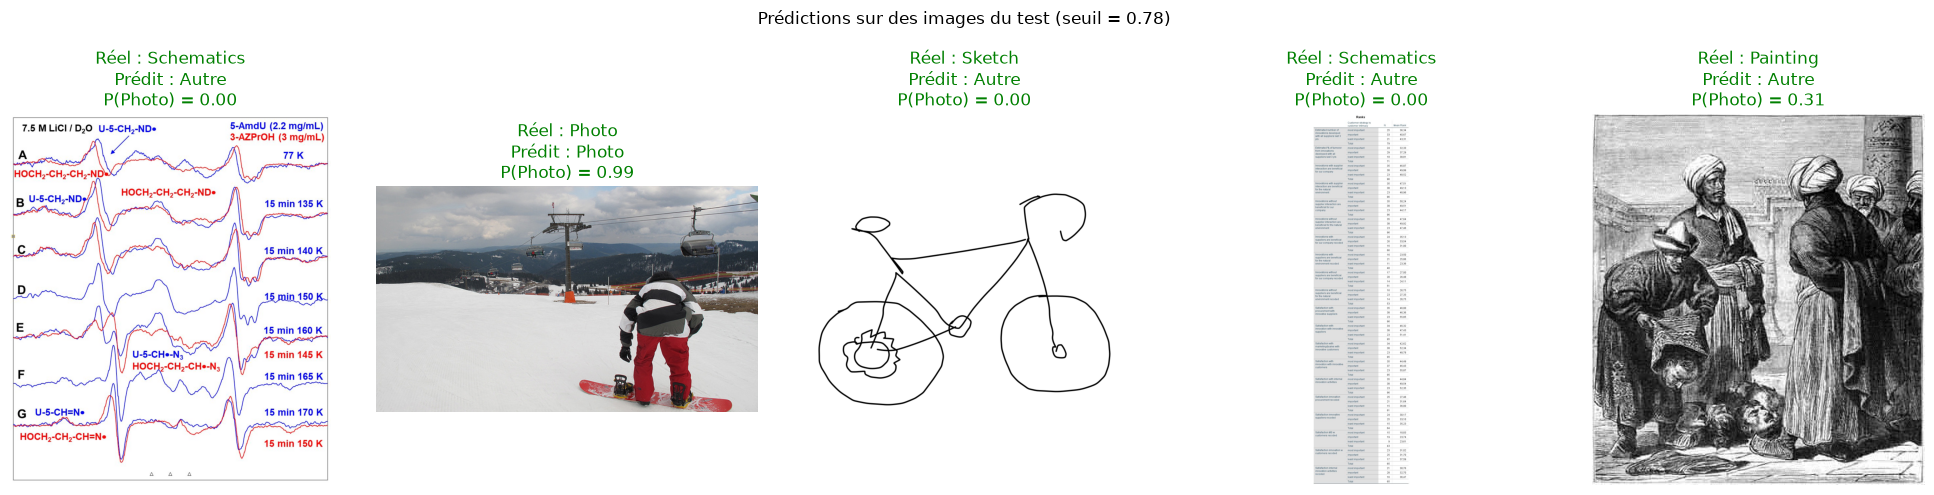

,image,catégorie réelle,prédiction,probabilité Photo,correct
0,schematics_05726.jpg,Schematics,Autre,0.0000,oui
1,photo_2290.jpg,Photo,Photo,0.9939,oui
2,1725.png,Sketch,Autre,0.0000,oui
3,schematics_00728.jpg,Schematics,Autre,0.0000,oui
4,painting_02600.jpg,Painting,Autre,0.3142,oui


In [90]:
# Catégorie réelle de chaque image du test, retrouvée à partir de son chemin
real_classes = df_test.set_index("path")["source_class"]


# Affichage des images de démonstration avec leur prédiction
def show_predictions(paths, model=best_model, threshold=DECISION_THRESHOLD):
    fig, axes = plt.subplots(1, len(paths), figsize=(4 * len(paths), 5))
    rows = []

    # Pour chaque image : prédiction, comparaison avec la vraie catégorie, affichage
    for ax, path in zip(np.atleast_1d(axes), paths):
        result = predict_image(path, model, threshold)
        real_class = real_classes[path]
        is_correct = (real_class == "Photo") == (result["prediction"] == "Photo")

        with Image.open(path) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(
            f"Réel : {real_class}\n"
            f"Prédit : {result['prediction']}\n"
            f"P(Photo) = {result['probabilité Photo']:.2f}",
            color="green" if is_correct else "red",
        )
        ax.axis("off")

        rows.append({
            "image": Path(path).name,
            "catégorie réelle": real_class,
            "prédiction": result["prediction"],
            "probabilité Photo": round(result["probabilité Photo"], 4),
            "correct": "oui" if is_correct else "non",
        })

    plt.suptitle(f"Prédictions sur des images du test (seuil = {threshold:.2f})")
    plt.tight_layout()
    plt.show()

    display(pd.DataFrame(rows))


show_predictions(demo_paths)

## 16. Sauvegarde du modèle et des paramètres

Le modèle final doit pouvoir être réutilisé sans refaire l’entraînement.

Nous sauvegardons :

- l’architecture ;
- les poids ;
- le seuil de décision ;
- la taille d’image ;
- les classes utilisées.

In [85]:
OUTPUT_DIR = Path("livrable1_artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)

model_path = OUTPUT_DIR / "modele_classification_photo_autre.keras"
metadata_path = OUTPUT_DIR / "parametres_classification.json"

best_model.save(model_path)

metadata = {
    "model_name": best_model_name,
    "image_size": list(IMAGE_SIZE),
    "decision_threshold": DECISION_THRESHOLD,
    "classes": {"0": "Autre", "1": "Photo"},
    "source_classes": SOURCE_CLASSES,
    "seed": SEED,
}

metadata_path.write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("Modèle sauvegardé :", model_path)
print("Paramètres sauvegardés :", metadata_path)

Modèle sauvegardé : livrable1_artifacts/modele_classification_photo_autre.keras
Paramètres sauvegardés : livrable1_artifacts/parametres_classification.json


## Conclusion

Le CNN à 4 blocs distingue correctement les photographies des autres types d'images. Sur le test final, il obtient une **accuracy de 93,67 %**, une **balanced accuracy de 90,94 %**, un **F1 macro de 0,9129**, une **ROC-AUC de 0,9783** et une **PR-AUC de 0,9367**. La balanced accuracy et le F1 macro sont particulièrement pertinents car la classe Autre est majoritaire. Le modèle dépasse nettement l'accuracy de référence d'un classifieur constant Autre, qui serait de **75,9 %**.

Le modèle généralise correctement : le F1 macro passe de **0,9094 sur la validation à 0,9129 sur le test**. La performance reste donc très proche entre les deux ensembles, ce qui suggère une bonne capacité de généralisation. Le seuil de décision **0,78** a été choisi uniquement sur la validation, où il permet d'obtenir un F1 macro de **0,9229**, puis a été réutilisé tel quel sur le test final afin d'éviter toute fuite d'information.

Les peintures restent la famille la plus difficile : **9,93 %** d'entre elles sont classées comme des photos. Le test contient également **215 faux négatifs sur 1 499 photographies**, soit un rappel Photo de **85,66 %**. La matrice de confusion confirme que le modèle reconnaît correctement la majorité des images, avec **4 533 images Autre correctement classées** et **1 284 photographies correctement identifiées**, mais certains cas restent ambigus, notamment entre les photographies et les peintures.

Le CNN de référence et le modèle régularisé sont moins performants que le CNN à 4 blocs et ne sont donc pas retenus comme modèle final. Le CNN à 4 blocs constitue le meilleur compromis obtenu dans cette expérience, notamment grâce à son F1 macro et à ses performances ROC-AUC et PR-AUC. Dans les prochains livrables, il faudra notamment étudier plus précisément les faux positifs provenant de la classe Painting, tester une approche par **transfer learning**, et vérifier l'impact des erreurs de classification sur le module de **captioning**.

**Références pédagogiques utilisées :**

- Workshop 1 : normalisation, compilation, entraînement, évaluation et sauvegarde Keras.
- Workshop 2 : CNN, Rescaling, convolution, pooling, dropout, augmentation et courbes d’apprentissage.
- Workshop 3 : reproductibilité, séparation stratifiée, métriques, matrices de confusion, comparaison sur validation et test final indépendant.